# State vectors and measurements



We can make use of the class <code>Statevector</code> to define a state vector of a qubit (in the computational base by default).  
The object <code>Statevector</code> has methods that allows to display the qubit state in **vector notation** or in **ket notation**.  

In [104]:
from qiskit.quantum_info import Statevector
from qiskit.visualization import array_to_latex
from math import sqrt, pi

# Define state vectors in vector notation (Z basis)
state_0 = [1, 0]
state_1 = [0, 1]

# instantiate the Statevector class objects
ket0 = Statevector(state_0)
ket1 = Statevector(state_1)

# Display statevectors in vector notation
print("Statevector ket0 : ",ket0.draw('text'))
print("Statevector ket1 : ",ket1.draw('text'))

Statevector ket0 :  [1.+0.j,0.+0.j]
Statevector ket1 :  [0.+0.j,1.+0.j]


Or equivalently, using latex:

In [105]:
print("Statevector ket0:")
display( array_to_latex(ket0))

print("Statevector ket1:")
display( array_to_latex(ket1))

Statevector ket0:


<IPython.core.display.Latex object>

Statevector ket1:


<IPython.core.display.Latex object>

But it will be better if we can display in ket notation. It is more compact and easy to read:

In [106]:
# Display statevectors in ket notation:

print("Statevector ket0:")
display( ket0.draw('latex'))

print("Statevector ket1:")
display( ket1.draw('latex'))


Statevector ket0:


<IPython.core.display.Latex object>

Statevector ket1:


<IPython.core.display.Latex object>

We can verify other properties of the statevector, such as if it is a valid Statevector.

In [107]:
## define another vector

ket2 = ket0
#ket2 = Statevector([1,1])
#ket2 = Statevector([0.8,0.6])

print("Statevector ket2:")
display(ket2.draw('latex'))

## check is valid
print("Is normalized? : ",ket2.is_valid())     # False


Statevector ket2:


<IPython.core.display.Latex object>

Is normalized? :  True


## The Block Sphere

Let's now explore a more visual representation of the qubit and its state.  

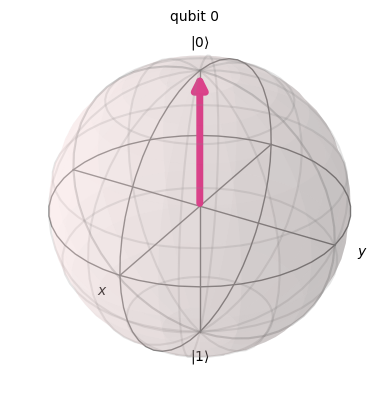

In [117]:
from qiskit.visualization import plot_bloch_multivector

state = ket2 #Statevector
plot_bloch_multivector(state)

# Measurements

Let's define a valid mixed state vector and do some measurements using the Statevector methods.  
The method```measure()``` returns the result of measurement and the remaining state vector.   
Remember that measurements are probabilistic, so runnig the same cell may output different results:

In [89]:
ket3_mix = Statevector([1/sqrt(2),1/sqrt(2)])

## Normalisation
display(ket3_mix.draw('latex'))
print("Is normalized? : ",ket3_mix.is_valid(),'\n')  

## measure
ket3_measure = ket3_mix.measure()
#print(type(ket3_measured),'\n')

measure_ket3 = ket3_measure[0]
ket3_remaining = ket3_measure[1] 

print(f'measurement output = {measure_ket3}')
print("remaining statevector:")
display(ket3_remaining.draw('latex'))

<IPython.core.display.Latex object>

Is normalized? :  True 

measurement output = 1
remaining statevector:


<IPython.core.display.Latex object>

So the measurement process changed the qubit state: it collapsed the state. This is a projective measurement.

In [91]:
## Now let's see what happens when we measure again the same statevector
ket4 = ket3_remaining

ket4_measurements = ket4.measure()
print(f'measurement output = {ket4_measurements[0]}')
print(f'remaining statevector = {ket4_measurements[1].draw("text")}')


ket4 = ket4_measurements[1]

ket4_measurements = ket4.measure()
print(f'measurement output = {ket4_measurements[0]}')
print(f'remaining statevector = {ket4_measurements[1].draw("text")}')


ket4 = ket4_measurements[1]

ket4_measurements = ket4.measure()
print(f'measurement output = {ket4_measurements[0]}')
print(f'remaining statevector = {ket4_measurements[1].draw("text")}')


ket4 = ket4_measurements[1]

ket4_measurements = ket4.measure()
print(f'measurement output = {ket4_measurements[0]}')
print(f'remaining statevector = {ket4_measurements[1].draw("text")}')


measurement output = 1
remaining statevector = [0.+0.j,1.+0.j]
measurement output = 1
remaining statevector = [0.+0.j,1.+0.j]
measurement output = 1
remaining statevector = [0.+0.j,1.+0.j]
measurement output = 1
remaining statevector = [0.+0.j,1.+0.j]


The wave function has collapsed after the very first measurement.  
Measurements like this one, break the superposition state.

## Initialize states

For our quantum programs, we will generally want to have several qubits that will work together to for a Quantum circuit.  
Additionally we will generally want the qubits in the quantum computer to start out in defined states.  
To do so, we use the ```QuantumCircuit``` class object and the ```initialize()``` method.

In [203]:
# import libraries to initialize a qubit in a Quantum Computer (* cloud service)
from qiskit import QuantumCircuit, Aer
from qiskit.visualization import plot_histogram 

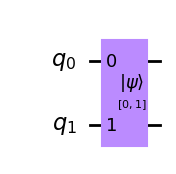

In [204]:
## Create a quantum circuit with one qubit
qc = QuantumCircuit(2)

## Define initial_state as |1>, this is the column vector [0,1]
initial_state = [0,1]   

## Apply initialisation operation to the 0th qubit
qc.initialize('01', qc.qubits) # the order must be inverted!

## Let's view our circuit
qc.draw()  

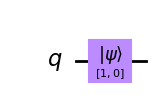

In [205]:
## Create a quantum circuit with one qubit
qc = QuantumCircuit(1)

## Define initial_state as |1>, this is the column vector [0,1]
initial_state = [1,0]   

## Apply initialisation operation to the 0th qubit
qc.initialize(initial_state, 0) 

## Let's view our circuit
qc.draw()  

Select a specific backend hardware to execute our circuit.
To get the results from our circuit, we use ```run()``` to execute our circuit, giving the circuit and the backend as arguments. We then use ```.result()``` to get the result of this:

In [206]:
sim = Aer.get_backend('aer_simulator')  # Tell Qiskit how to simulate our circuit
qc.save_statevector()   # Tell simulator to save statevector
result = sim.run(qc).result() # Do the simulation and return the result

from result, we can then get the final statevector using .get_statevector():

In [207]:
out_state = result.get_statevector()

## Three ways of visualizing the vector
print("Qubit initialized on state:")
display(out_state.draw('latex'))


Qubit initialized on state:


<IPython.core.display.Latex object>

Let’s now measure our qubit and see the result of the measurement process:

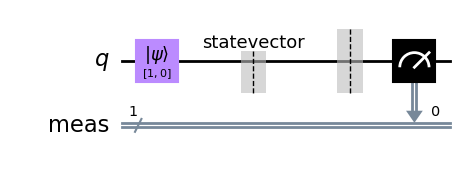

In [208]:
qc.measure_all()
qc.draw()

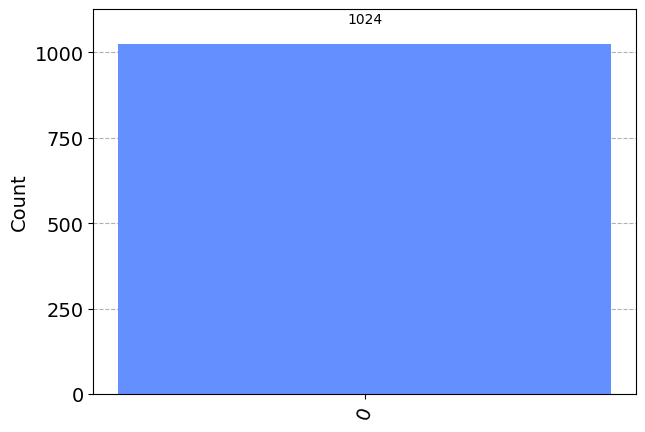

In [209]:

result = sim.run(qc).result()
counts = result.get_counts()
plot_histogram(counts)

## Superposition

let’s instead put our qubit into a superposition and see what happens. 
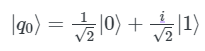

In [210]:
# Define state for |q_0>
initial_state = [1/sqrt(2), 1j/sqrt(2)]  

## define the circuit
qc = QuantumCircuit(1) # Must redefine qc

# Initialize the 0th qubit in the state `initial_state`
qc.initialize(initial_state, 0) 
qc.save_statevector() # Save statevector

# Execute the circuit
state = sim.run(qc).result().get_statevector() 
print("Our circuit is prepared in state:")
display(state.draw('latex'))           # Print the result

Our circuit is prepared in state:


<IPython.core.display.Latex object>

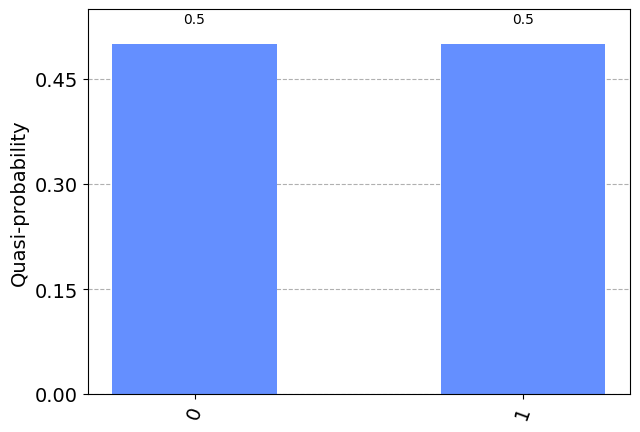

In [211]:
# Execute measurements and get results
results = sim.run(qc).result().get_counts()

result = sim.run(qc).result()
counts = result.get_counts()

# visualization
plot_histogram(counts)

We can see we have 50% probability of measuring  compared to . To explain this, we need to talk about measurement.

## The Rule of Measurements
To find the probability of measuring a state $|\psi\rangle$ in the state $|x\rangle$ we do:
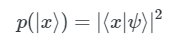
This is the Born rule.
It has some implications:  
1- State must be normalized  

 

In [249]:
# if not normalized, the initialization gives an error
vector = [1,1]
qc.initialize(vector, 0)


Traceback (most recent call last):
  Cell In[249], line 3
    qc.initialize(vector, 0)
  File /opt/conda/lib/python3.10/site-packages/qiskit/extensions/quantum_initializer/initializer.py:191 in initialize
    return self.append(Initialize(params, num_qubits), qubits)
  File /opt/conda/lib/python3.10/site-packages/qiskit/extensions/quantum_initializer/initializer.py:57 in __init__
    self._stateprep = StatePreparation(params, num_qubits)
  File /opt/conda/lib/python3.10/site-packages/qiskit/circuit/library/data_preparation/state_preparation.py:99 in __init__
    num_qubits = self._get_num_qubits(num_qubits, params)
  File /opt/conda/lib/python3.10/site-packages/qiskit/circuit/library/data_preparation/state_preparation.py:202 in _get_num_qubits
    raise QiskitError("Sum of amplitudes-squared does not equal one.")
QiskitError: 'Sum of amplitudes-squared does not equal one.'

Use %tb to get the full traceback.


2- We can project in any state x, not only in 0 or 1.  
3- Global phase do not matter  


4- The observer effect: wavefunction collapse. 
We know that the amplitudes contain information about the probability of us finding the qubit in a specific state, but once we have measured the qubit, we know with certainty what the state of the qubit is.  
This means the act of measuring changes the state of our qubits.

We sometimes refer to this as collapsing the state of the qubit. It is a potent effect, and so one that must be used wisely.

We can demonstrate this using Qiskit’s statevector simulator:

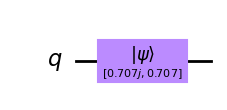

In [250]:
qc = QuantumCircuit(1) # We are redefining qc

initial_state = [0.+1.j/sqrt(2),1/sqrt(2)+0.j]
qc.initialize(initial_state, 0)

qc.draw()

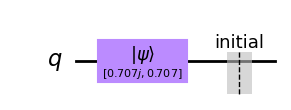

In [251]:
#We can same the state vector before starting operations: 

qc.save_statevector(label="initial")
qc.draw()

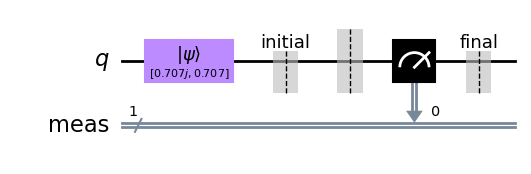

In [252]:
#After having created the circuit, Let’s now measure this qubit:
qc.measure_all()

# save statevector after measurement
qc.save_statevector(label="final")

qc.draw()

When we simulate this entire circuit, we can see that one of the amplitudes is always 0:  
(You can re-run this cell a few times to reinitialize the qubit and measure it again.)

In [258]:
#state = sim.run(qc).result().get_statevector(['end'])
result = sim.run(qc).result() 

initial = result.data(0)["initial"]
final = result.data(0)["final"]

print("State before measurement = ")
display(initial.draw('latex'))

print("State after measurement = ")
display(final.draw('latex'))

State before measurement = 


<IPython.core.display.Latex object>

State after measurement = 


<IPython.core.display.Latex object>